### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# Fig 3A · SLC38A4 CRISPR-KO confirmation by RT-qPCR

**Main panel (Fig 3A):** SLC38A4 expression measured with a primer set targeting the **C-terminus** of the transcript.
**Supplementary panel (Fig S6C):** TaqMan assay targeting the **CRISPR guide-RNA region** (near-complete loss).

Expression is normalised to the WT scramble control (= 1). Groups: **WT** (scramble ctrl), **KO 1** (clone **C12**),
**KO 2** (clone **P1.7**); clones ordered alphabetically to match the RNA-seq/limma convention. n = 6 per group.

**Statistics:** unpaired Welch's t-test on log₂-transformed relative expression (WT vs each KO clone), uncorrected;
exact p-values shown. Data are embedded below as a clean tidy dataframe (no external file required).

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# --- plotting settings (shared): Helvetica, base font 10, axis titles 11 ---
AXTITLE = 11
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'axes.unicode_minus': False,
})

In [3]:
# --- load plotted data (tidy CSV, one row per replicate; KO 1 = C12, KO 2 = P1.7) ---
qpcr = pd.read_csv('Fig3A_KO_confirmation_data.csv')
print(qpcr.groupby(['probe', 'group'])['rel_expression'].agg(['count', 'mean', 'std']).round(3))
qpcr.head()

                         count   mean    std
probe             group                     
C-terminus region KO 1       6  0.205  0.050
                  KO 2       6  0.310  0.020
                  WT         6  1.000  0.128
CRISPR KO region  KO 1       6  0.140  0.019
                  KO 2       6  0.018  0.004
                  WT         6  1.000  0.066


,probe,panel,group,clone,replicate,rel_expression
0,C-terminus region,Fig 3A (main),WT,scramble ctrl,1,0.86
1,C-terminus region,Fig 3A (main),WT,scramble ctrl,2,1.03
2,C-terminus region,Fig 3A (main),WT,scramble ctrl,3,0.99
3,C-terminus region,Fig 3A (main),WT,scramble ctrl,4,0.85
4,C-terminus region,Fig 3A (main),WT,scramble ctrl,5,1.10


In [4]:
# --- shared helpers + panel builder ---
GROUP_ORDER = ['WT', 'KO 1', 'KO 2']
COLORS      = ['#AAAAAA', '#D73027', '#FC8D59']   # WT grey; KO 1 dark red, KO 2 salmon

def sem(x): return x.std(ddof=1) / np.sqrt(len(x))
def fmt_p(p): return f'p = {p:.1e}' if p < 1e-4 else f'p = {p:.4f}'
def sig_bracket(ax, x1, x2, y, h, text, fontsize=7):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='black', lw=0.8, clip_on=False, zorder=5)
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=fontsize, rotation=0)

def make_panel(probe, out_pdf, axtitle=AXTITLE, ticksize=None, pfontsize=7, spacing=1.0, width=0.6, xpad=0.5, figsize=(3, 3), pad_inches=0.1, ylabel='Relative SLC38A4 mRNA expression\n(fold change vs WT)', ymax=1.2):
    sub = qpcr[qpcr.probe == probe]
    wt  = sub[sub.group == 'WT']['rel_expression'].values
    # stats: Welch's t-test on log2 relative expression, WT vs each KO
    rows = []
    for ko in ['KO 1', 'KO 2']:
        kv = sub[sub.group == ko]['rel_expression'].values
        t, p = stats.ttest_ind(np.log2(wt), np.log2(kv), equal_var=False)
        rows.append({'Comparison': f'WT vs {ko}', 'clone': sub[sub.group == ko]['clone'].iloc[0],
                     'n (WT)': len(wt), 'n (KO)': len(kv),
                     'Mean WT': round(wt.mean(), 4), 'Mean KO': round(kv.mean(), 4),
                     't': round(float(t), 3), 'p': p})
    sdf = pd.DataFrame(rows); pl = {r.Comparison: r.p for _, r in sdf.iterrows()}
    # figure
    positions = [gi * spacing for gi in range(len(GROUP_ORDER))]
    fig, ax = plt.subplots(figsize=figsize)
    tops = []
    for gi, (grp, col) in enumerate(zip(GROUP_ORDER, COLORS)):
        x = positions[gi]
        vals = sub[sub.group == grp]['rel_expression'].values
        mn, se = vals.mean(), sem(vals)
        ax.bar(x, mn, width=width, color=col, alpha=0.65, edgecolor='black', linewidth=0.8, zorder=2)
        ax.errorbar(x, mn, yerr=se, color='black', linewidth=1.2, capsize=3, capthick=1.2, ls='none', zorder=3)
        off = np.linspace(-0.16, 0.16, len(vals))
        ax.scatter(x + off, vals, color=col, edgecolors='black', linewidth=0.5, s=20, zorder=4, alpha=0.9)
        tops.append(max(mn + se, vals.max()))
    # significance brackets, WT vs each KO -- staggered heights, matching Fig 3F/3J style
    top = max(tops)
    headroom = ymax - top
    tick_h = headroom * 0.08
    y_levels = [top + headroom * 0.15, top + headroom * 0.65]
    for (xi, ko), y in zip([(1, 'KO 1'), (2, 'KO 2')], y_levels):
        x = positions[xi]
        sig_bracket(ax, positions[0], x, y, tick_h, fmt_p(pl[f'WT vs {ko}']), fontsize=pfontsize)
    ax.set_xticks(positions); ax.set_xticklabels(['WT', 'KO 1', 'KO 2'])
    if ticksize is not None:
        ax.tick_params(axis='both', labelsize=ticksize)
    ax.set_ylabel(ylabel, fontsize=axtitle)
    ax.set_xlim(positions[0] - xpad, positions[-1] + xpad); ax.set_ylim(0, ymax)
    plt.tight_layout()
    fig.savefig(out_pdf, bbox_inches='tight', pad_inches=pad_inches); plt.show()
    print('Saved:', out_pdf)
    return sdf


## Main figure — Fig 3A (C-terminus primer set)

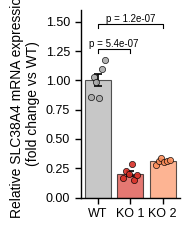

Saved: Fig3A_SLC38A4_KO_confirmation.pdf


,Comparison,clone,n (WT),n (KO),Mean WT,Mean KO,t,p
0,WT vs KO 1,C12,6,6,1.0,0.205,14.759,5.401486e-07
1,WT vs KO 2,P1.7,6,6,1.0,0.310,19.752,1.207963e-07


In [5]:
stats_main = make_panel('C-terminus region', 'Fig3A_SLC38A4_KO_confirmation.pdf', axtitle=10, ticksize=9, pfontsize=7, spacing=0.75, width=0.6, xpad=0.4, figsize=(2, 2.4), pad_inches=0.28, ylabel='Relative SLC38A4 mRNA expression\n(fold change vs WT)', ymax=1.6)
stats_main[['Comparison','clone','n (WT)','n (KO)','Mean WT','Mean KO','t','p']]

## Supplementary figure — Fig S6C (CRISPR guide-RNA target region, TaqMan)

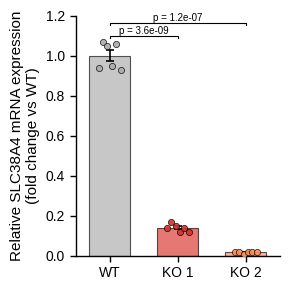

Saved: Fig_S6C_SLC38A4_KO_TaqMan.pdf


,Comparison,clone,n (WT),n (KO),Mean WT,Mean KO,t,p
0,WT vs KO 1,C12,6,6,1.0,0.1400,32.314,3.631099e-09
1,WT vs KO 2,P1.7,6,6,1.0,0.0183,33.925,1.194009e-07


In [6]:
stats_supp = make_panel('CRISPR KO region', 'Fig_S6C_SLC38A4_KO_TaqMan.pdf')
stats_supp[['Comparison','clone','n (WT)','n (KO)','Mean WT','Mean KO','t','p']]